# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Computer Vision Lab** | Registration No: **030** | Total: 25 marks

**Goal:** build two classical pipelines (HOG + SVM and SIFT + SVM) for 4 blood-cell classes and find out which is more reliable when images are **rotated** or **noisy**.

**Notebook flow:** settings -> Q1 data -> Q2 HOG+SVM -> Q3 SIFT+SVM -> Q4 robustness (test set used *only* here) -> Q5 short answers + AI log.

## Personal Settings (derived from registration number 030)
| Setting | Rule | Result for 030 |
|---|---|---|
| Random seed | last two digits | **30** |
| HOG cell size | last digit 0 is even -> 8x8 | **8 x 8** |
| SIFT grid | last digit 0 is in 0-4 -> 4x4 grid | **4 x 4 = 16 keypoints** |

The cell below computes these from the registration number with code, so the rule is visible and nothing is hard-typed by mistake.

In [ ]:
import os, glob, warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore")


REG_NO = "030"
SEED = int(REG_NO[-2:])                              # last two digits -> 30
last_digit = int(REG_NO[-1])                         # 0
HOG_CELL = (8, 8) if last_digit % 2 == 0 else (16, 16)
GRID_N = 4 if last_digit <= 4 else 6                 # 4x4 -> 16 keypoints, 6x6 -> 36


KEEP_CLASSES = [1, 5, 6, 7]                          # original BloodMNIST label ids
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_TRAIN, N_VAL, N_TEST = 100, 30, 30
IMG_SIZE = 128
C_GRID = [0.1, 1, 10]
ROT_DEG = 20
NOISE_SIGMA = 0.05
KP_SIZE = 32

np.random.seed(SEED)
print(f"Reg no {REG_NO} -> seed={SEED}, HOG cell={HOG_CELL}, SIFT grid={GRID_N}x{GRID_N} ({GRID_N**2} keypoints)")

Reg no 030 -> seed=30, HOG cell=(8, 8), SIFT grid=4x4 (16 keypoints)


# Q1. Data setup (3 marks)
**What we do:** download BloodMNIST, keep only 4 classes (eosinophil=1, monocyte=5, neutrophil=6, platelet=7), and sample **100 train / 30 val / 30 test** images per class using our seed (so the subset is reproducible). Labels are remapped from {1,5,6,7} to {0,1,2,3}.

**Why a seeded subset:** a small subset keeps training fast on a laptop; the seed makes sure the same images are chosen every time we run the notebook.

In [91]:
import os, glob, warnings
import numpy as np
from PIL import Image

data = {}

def load_from_folders(root):
    # If the directory contains subdirectories train, val, test with images
    try:
        for split in ["train", "val", "test"]:
            split_dir = os.path.join(root, split)
            if not os.path.isdir(split_dir):
                return None

            images = []
            labels = []
            # find subfolders (classes)
            classes = sorted([d for d in os.listdir(split_dir) if os.path.isdir(os.path.join(split_dir, d))])
            if not classes:
                # maybe direct images?
                continue

            for class_label in classes:
                try:
                    val_label = int(class_label)
                except ValueError:
                    # mapping class folder names to integer labels if they are named like '0', '1', etc.
                    continue
                class_dir = os.path.join(split_dir, class_label)
                for img_name in sorted(os.listdir(class_dir)):
                    img_path = os.path.join(class_dir, img_name)
                    if img_path.lower().endswith(('.png', '.jpg', '.jpeg')):
                        with Image.open(img_path) as im:
                            images.append(np.array(im.convert('RGB')))
                        labels.append([val_label])

            if len(images) > 0:
                data[f"{split}_images"] = np.array(images)
                data[f"{split}_labels"] = np.array(labels)

        if "train_images" in data and "val_images" in data and "test_images" in data:
            print("Successfully loaded dataset from split directories!")
            return data
    except Exception as e:
        print("Error loading from folders:", e)
    return None

# ---- Check Kaggle directory ----
DATA_DIR = "/kaggle/input/bloodmnist"
if os.path.exists(DATA_DIR):
    print("Checking Kaggle folder structure...")
    loaded_data = load_from_folders(DATA_DIR)
    if loaded_data:
        data = loaded_data

# ---- Fallback to MedMNIST pip library (Forcing size=64 as required by the exam) ----
if not data:
    print("No folder structured data found. Falling back to downloading via the medmnist package with size=64...")
    !pip install -q -U medmnist
    from medmnist import BloodMNIST

    for split in ["train", "val", "test"]:
        dataset = BloodMNIST(split=split, download=True, size=64)
        data[f"{split}_images"] = dataset.imgs
        data[f"{split}_labels"] = dataset.labels

for k, v in data.items():
    print(k, v.shape)

Checking Kaggle folder structure...
No folder structured data found. Falling back to downloading via the medmnist package with size=64...
train_images (11959, 64, 64, 3)
train_labels (11959, 1)
val_images (1712, 64, 64, 3)
val_labels (1712, 1)
test_images (3421, 64, 64, 3)
test_labels (3421, 1)


In [92]:
# ---- Image preparation: grayscale + resize to 128x128 ----
def prepare(img):
    if img.ndim == 3 and img.shape[2] == 3:
        img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    elif img.ndim == 3:
        img = img[..., 0]
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    return img.astype(np.uint8)

# ---- Seeded subset: n images per class from each official split ----
rng = np.random.RandomState(SEED)

def make_subset(split, n_per_class):
    imgs, labs = data[f"{split}_images"], data[f"{split}_labels"].ravel()
    X, y = [], []
    for new_label, orig in enumerate(KEEP_CLASSES):
        idx = np.where(labs == orig)[0]
        assert len(idx) >= n_per_class, f"not enough images of class {orig} in {split}"
        chosen = rng.choice(idx, n_per_class, replace=False)
        X += [prepare(imgs[i]) for i in chosen]
        y += [new_label] * n_per_class
    return np.array(X), np.array(y)

X_train, y_train = make_subset("train", N_TRAIN)
X_val,   y_val   = make_subset("val",   N_VAL)
X_test,  y_test  = make_subset("test",  N_TEST)

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    counts = {CLASS_NAMES[c]: int((y == c).sum()) for c in range(4)}
    print(f"{name:5s} X shape={X.shape}, dtype={X.dtype}, y shape={y.shape}, class counts={counts}")

train X shape=(400, 128, 128), dtype=uint8, y shape=(400,), class counts={'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   X shape=(120, 128, 128), dtype=uint8, y shape=(120,), class counts={'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  X shape=(120, 128, 128), dtype=uint8, y shape=(120,), class counts={'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


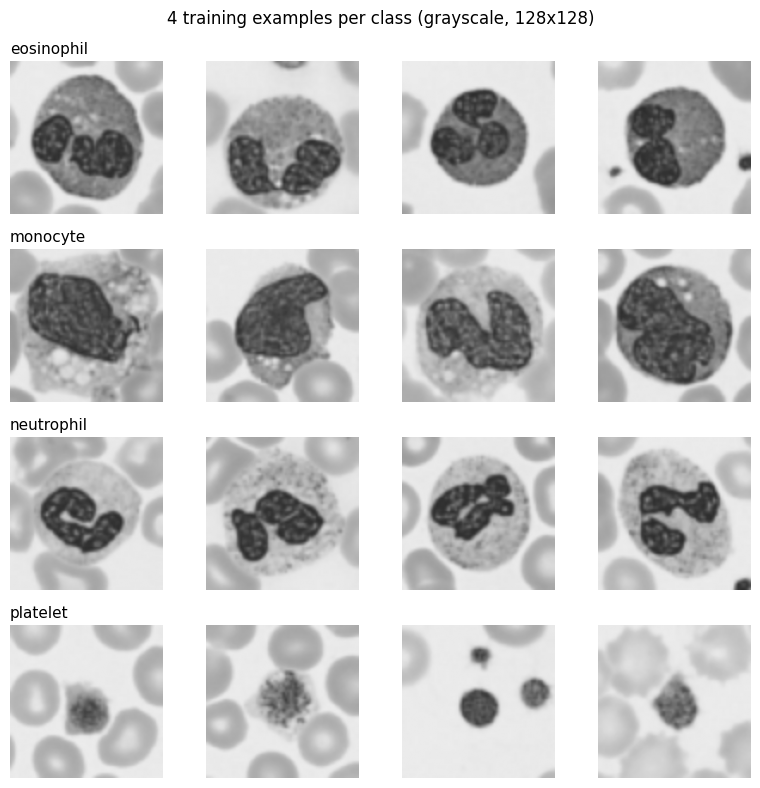

In [93]:
# ---- Grid: 4 example images per class ----
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for c in range(4):
    idx = np.where(y_train == c)[0][:4]
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_train[i], cmap="gray", vmin=0, vmax=255)
        axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_title(CLASS_NAMES[c], loc="left", fontsize=11)
plt.suptitle("4 training examples per class (grayscale, 128x128)")
plt.tight_layout(); plt.show()

## Shared helper: train an SVM and choose C on the validation set
For each C in {0.1, 1, 10} we fit a `LinearSVC` on the **training** set and measure accuracy on the **validation** set. The C with the best validation accuracy is kept (ties -> the smaller C, i.e. the simpler model). The test set is **not touched** here.

A `StandardScaler` (fitted on training data only) is placed in front of the SVM inside a pipeline. It puts every feature on a similar scale, which helps `LinearSVC` converge, and it is still just a linear SVM underneath. Because it is in a pipeline, the whole "frozen" model can later be applied to test images in one call.

In [94]:
def train_svm(Xtr, ytr, Xva, yva, tag):
    rows, best = [], None
    for C in C_GRID:
        model = make_pipeline(StandardScaler(),
                              LinearSVC(C=C, max_iter=20000, random_state=SEED))
        model.fit(Xtr, ytr)
        acc = accuracy_score(yva, model.predict(Xva))
        rows.append({"C": C, "val_accuracy": round(acc, 4)})
        if best is None or acc > best[0]:      # strict '>' keeps the smaller C on ties
            best = (acc, C, model)
    print(f"[{tag}] validation accuracy for each C:")
    print(pd.DataFrame(rows).to_string(index=False))
    acc, C, model = best
    pred = model.predict(Xva)
    f1 = f1_score(yva, pred, average="macro")
    cm = confusion_matrix(yva, pred)
    print(f"\n[{tag}] chosen C = {C}")
    print(f"[{tag}] validation accuracy = {acc:.4f}")
    print(f"[{tag}] validation macro-F1  = {f1:.4f}")
    print(f"[{tag}] confusion matrix (rows=true, cols=predicted; order={CLASS_NAMES}):")
    print(cm)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{tag}: validation confusion matrix")
    plt.tight_layout(); plt.show()
    return model, C, acc, f1, cm

# Q2. HOG + SVM (6 marks)
## Q2(a) HOG features and the feature length (2 marks)
HOG (Histogram of Oriented Gradients) splits the image into small cells, builds a histogram of gradient directions (9 orientations) in each cell, then groups cells into overlapping blocks (2x2 cells) and normalises each block. All block histograms are concatenated into one vector.

In [95]:
def hog_feat(img):
    return hog(img, orientations=9, pixels_per_cell=HOG_CELL,
               cells_per_block=(2, 2), block_norm="L2-Hys",
               feature_vector=True)

feat_demo = hog_feat(X_train[0])
print("HOG feature length from code:", feat_demo.shape[0])

HOG feature length from code: 8100


### Hand calculation of the HOG feature length
- Image = 128 x 128, cell = 8 x 8 pixels -> cells per side = 128 / 8 = **16**, so a 16 x 16 grid of cells.
- Block = 2 x 2 cells, sliding by 1 cell -> blocks per side = 16 - 2 + 1 = **15**, so 15 x 15 = **225 blocks**.
- Each block holds 2 x 2 cells x 9 orientations = **36 values**.
- Total = 225 x 36 = **8100** features.

The code output above must show 8100 (a quick check that the hand calculation and the library agree).

In [96]:
cells_per_side = IMG_SIZE // HOG_CELL[0]
blocks_per_side = cells_per_side - 2 + 1
by_hand = blocks_per_side**2 * (2*2*9)
print(f"cells/side={cells_per_side}, blocks/side={blocks_per_side}, by hand={by_hand}, code={feat_demo.shape[0]}")
assert by_hand == feat_demo.shape[0]

cells/side=16, blocks/side=15, by hand=8100, code=8100


## Q2(b) HOG pictures, one image per class (1 mark)
For each class the HOG picture shows short oriented strokes in every 8x8 cell. The strokes are bright and dense along the outline of the cell and nucleus, where gradients are strong, and faint in the flat background.

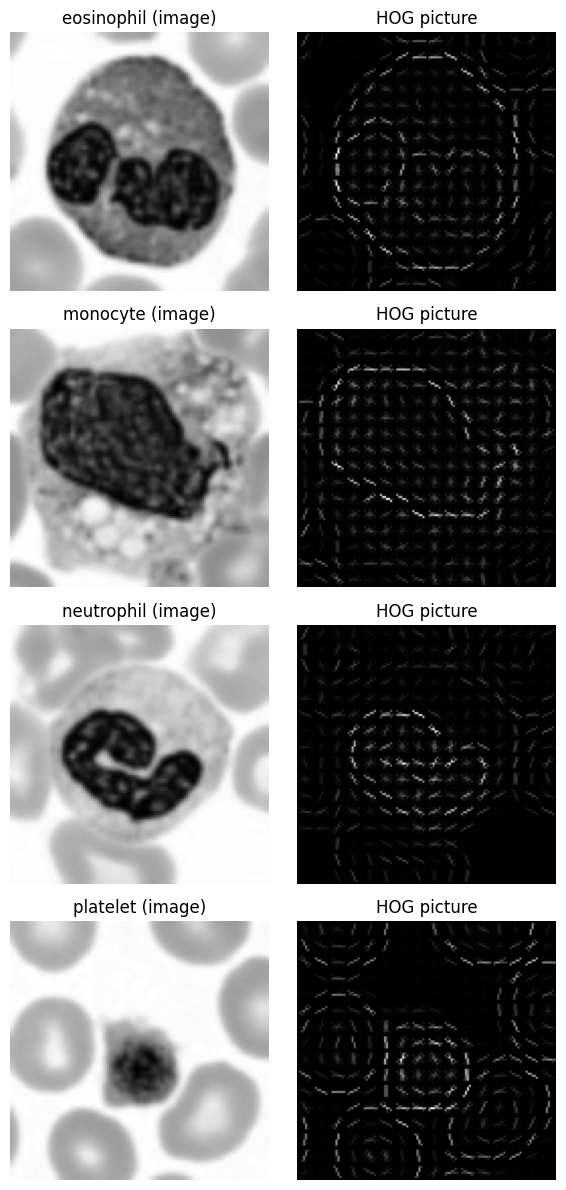

In [97]:
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for c in range(4):
    img = X_train[np.where(y_train == c)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=HOG_CELL,
                     cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    axes[c, 0].imshow(img, cmap="gray"); axes[c, 0].set_title(f"{CLASS_NAMES[c]} (image)"); axes[c, 0].axis("off")
    axes[c, 1].imshow(hog_img, cmap="gray"); axes[c, 1].set_title("HOG picture"); axes[c, 1].axis("off")
plt.tight_layout(); plt.show()

## Q2(c) Train HOG + SVM, choose C on validation (3 marks)

HOG feature matrices: (400, 8100) (120, 8100)
[HOG+SVM] validation accuracy for each C:
   C  val_accuracy
 0.1         0.725
 1.0         0.725
10.0         0.725

[HOG+SVM] chosen C = 0.1
[HOG+SVM] validation accuracy = 0.7250
[HOG+SVM] validation macro-F1  = 0.7258
[HOG+SVM] confusion matrix (rows=true, cols=predicted; order=['eosinophil', 'monocyte', 'neutrophil', 'platelet']):
[[20  4  5  1]
 [11 17  2  0]
 [ 7  3 20  0]
 [ 0  0  0 30]]


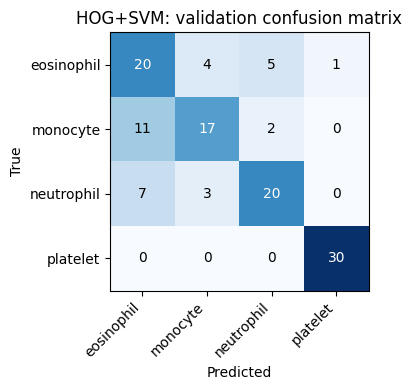

In [98]:
Xtr_hog = np.array([hog_feat(im) for im in X_train])
Xva_hog = np.array([hog_feat(im) for im in X_val])
print("HOG feature matrices:", Xtr_hog.shape, Xva_hog.shape)

hog_model, hog_C, hog_val_acc, hog_val_f1, hog_cm = train_svm(Xtr_hog, y_train, Xva_hog, y_val, "HOG+SVM")

# Q3. SIFT + SVM (7 marks)
## Q3(a) Normal SIFT detection on training images (2 marks)
SIFT normally *detects* its own keypoints (blobs/corners) with `detectAndCompute`. The number found depends on image content.

In [99]:
sift = cv2.SIFT_create()
kp_counts, zero_imgs = [], 0
for im in X_train:
    kps, desc = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
    if desc is None or len(kps) == 0:
        zero_imgs += 1
kp_counts = np.array(kp_counts)
print(f"Keypoints per image -> average: {kp_counts.mean():.2f}, min: {kp_counts.min()}, max: {kp_counts.max()}")
print(f"Images with zero keypoints: {zero_imgs} out of {len(X_train)}")

Keypoints per image -> average: 72.90, min: 6, max: 162
Images with zero keypoints: 0 out of 400


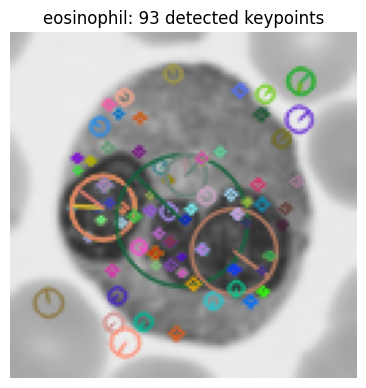

In [100]:
# draw keypoints on one image (first training image with at least one keypoint)
i0 = int(np.argmax(kp_counts > 0))
kps0, _ = sift.detectAndCompute(X_train[i0], None)
vis = cv2.drawKeypoints(X_train[i0], kps0, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4.5, 4.5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"{CLASS_NAMES[y_train[i0]]}: {len(kps0)} detected keypoints"); plt.show()

**Why a different number of keypoints is a problem for an SVM:** an SVM needs every sample to be a feature vector of the *same fixed length*, but each image gives (number of keypoints x 128) values, so the vectors have different lengths (and some images may have none), which cannot be fed to the SVM directly.

## Q3(b) Fix: a fixed grid of keypoints (2 marks)
Instead of letting SIFT detect keypoints, we place keypoints on a regular **4 x 4 grid** over the 128 x 128 image (cell centres at 16, 48, 80, 112 px), each with keypoint size 32, and use `sift.compute` to get a 128-d descriptor at each. Every image now gives exactly 16 descriptors, which we concatenate into one vector. A grid also guarantees we describe the whole cell region, even where SIFT would find nothing.

In [101]:
def make_grid_keypoints(n=GRID_N, size=IMG_SIZE, kp_size=KP_SIZE):
    step = size / n
    centres = (np.arange(n) + 0.5) * step          # centre of each grid cell
    return [cv2.KeyPoint(float(x), float(y), kp_size) for y in centres for x in centres]

grid_kps = make_grid_keypoints()
print("Grid keypoint coordinates (x, y):", [(int(k.pt[0]), int(k.pt[1])) for k in grid_kps])

def sift_feat(img):
    # new KeyPoint objects each call, because compute() may modify them
    kps, desc = sift.compute(img, make_grid_keypoints())
    assert desc is not None and desc.shape == (GRID_N**2, 128), f"unexpected descriptor shape {None if desc is None else desc.shape}"
    return desc.reshape(-1).astype(np.float32)

demo = sift_feat(X_train[0])
print("SIFT grid feature length from code:", demo.shape[0])

Grid keypoint coordinates (x, y): [(16, 16), (48, 16), (80, 16), (112, 16), (16, 48), (48, 48), (80, 48), (112, 48), (16, 80), (48, 80), (80, 80), (112, 80), (16, 112), (48, 112), (80, 112), (112, 112)]
SIFT grid feature length from code: 2048


### Hand calculation of the SIFT feature length
- Grid = 4 x 4 = **16 grid points** (keypoints).
- Each SIFT descriptor has **128** numbers (4 x 4 spatial bins x 8 orientations).
- Feature length = 16 x 128 = **2048**.

The code output above must show 2048.

by hand: 2048 | code: 2048


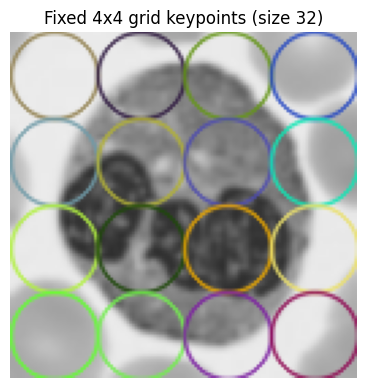

In [102]:
print("by hand:", GRID_N**2 * 128, "| code:", demo.shape[0])
assert GRID_N**2 * 128 == demo.shape[0]

# draw the grid keypoints on one image (sanity picture)
vis = cv2.drawKeypoints(X_train[0], make_grid_keypoints(), None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4.5, 4.5)); plt.imshow(vis[..., ::-1]); plt.axis("off"); plt.title("Fixed 4x4 grid keypoints (size 32)"); plt.show()

## Q3(c) Train SIFT + SVM, choose C on validation (3 marks)

SIFT feature matrices: (400, 2048) (120, 2048)
[SIFT+SVM] validation accuracy for each C:
   C  val_accuracy
 0.1        0.7833
 1.0        0.7750
10.0        0.7667

[SIFT+SVM] chosen C = 0.1
[SIFT+SVM] validation accuracy = 0.7833
[SIFT+SVM] validation macro-F1  = 0.7802
[SIFT+SVM] confusion matrix (rows=true, cols=predicted; order=['eosinophil', 'monocyte', 'neutrophil', 'platelet']):
[[18  6  5  1]
 [ 7 22  1  0]
 [ 2  3 24  1]
 [ 0  0  0 30]]


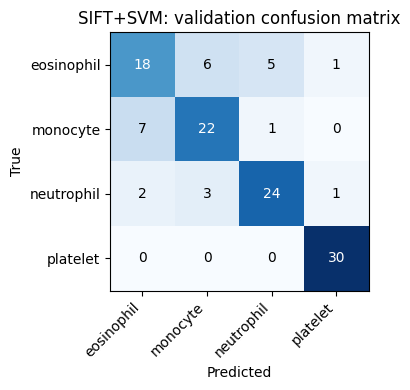

In [103]:
Xtr_sift = np.array([sift_feat(im) for im in X_train])
Xva_sift = np.array([sift_feat(im) for im in X_val])
print("SIFT feature matrices:", Xtr_sift.shape, Xva_sift.shape)

sift_model, sift_C, sift_val_acc, sift_val_f1, sift_cm = train_svm(Xtr_sift, y_train, Xva_sift, y_val, "SIFT+SVM")

# Q4. Robustness (6 marks)
## Q4(a) Prediction written BEFORE running the experiment (1 mark)

- **Rotation - I think HOG will lose more accuracy.** HOG stores the gradient direction in fixed positions of a fixed grid; after a 20 degree rotation every gradient direction shifts into different orientation bins and edges move into different cells, so the feature vector changes a lot. Grid-SIFT descriptors are computed over a larger 32x32 Gaussian-weighted patch with coarse 4x4 spatial bins, so a 20 degree turn changes them less.
- **Noise - I think HOG will lose more accuracy.** HOG uses 8x8 pixel cells computed directly from raw pixel gradients, and noise creates many random small gradients that add up in every histogram. SIFT's descriptor is computed on a Gaussian-smoothed image over a larger window, which averages out much of the noise.

## Q4(b) Freeze both models and evaluate: clean / rotated 20 deg / noisy (4 marks)
Both models are already trained and are **not refitted**. The test images are changed **first** (rotation or noise), then features are extracted, then the frozen model predicts.

- **Rotation:** `cv2.warpAffine` rotating 20 degrees about the image centre; border pixels filled with `BORDER_REFLECT_101` so no artificial black corners (which would add strong fake edges) appear.
- **Noise:** image scaled to 0-1, Gaussian noise with sigma = 0.05 added, clipped to [0,1], and converted back to 8-bit (SIFT needs uint8). A seeded random generator makes the noise reproducible.

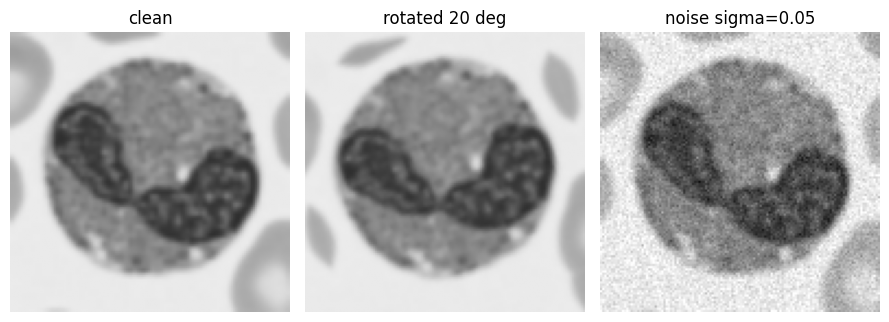

In [104]:
def rotate_img(img, deg=ROT_DEG):
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), deg, 1.0)
    return cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REFLECT_101)

noise_rng = np.random.RandomState(SEED)
def noisy_img(img, sigma=NOISE_SIGMA):
    x = img.astype(np.float32) / 255.0
    x = np.clip(x + noise_rng.normal(0, sigma, x.shape), 0, 1)
    return np.round(x * 255).astype(np.uint8)

X_test_rot   = np.array([rotate_img(im) for im in X_test])
X_test_noisy = np.array([noisy_img(im) for im in X_test])

# visual check: clean vs rotated vs noisy
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, im, t in zip(axes, [X_test[0], X_test_rot[0], X_test_noisy[0]], ["clean", f"rotated {ROT_DEG} deg", f"noise sigma={NOISE_SIGMA}"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

Test-set accuracy (120 test images):


,Clean accuracy,Rotated accuracy,Noisy accuracy
Model,,,
HOG + SVM,0.7500,0.7750,0.2500
SIFT + SVM,0.7083,0.7417,0.7167


Accuracy drop (clean - changed); larger = less robust:


,Drop under rotation,Drop under noise
Model,,
HOG + SVM,-0.0250,0.5000
SIFT + SVM,-0.0333,-0.0083


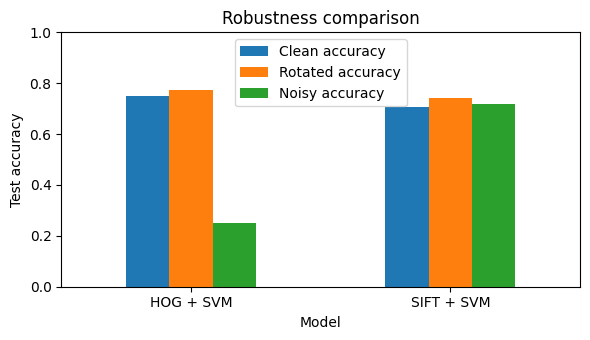

In [105]:
def test_acc(model, feat_fn, X):
    F = np.array([feat_fn(im) for im in X])      # features AFTER the image change
    return accuracy_score(y_test, model.predict(F))

results = []
for name, model, fn in [("HOG + SVM", hog_model, hog_feat), ("SIFT + SVM", sift_model, sift_feat)]:
    results.append({"Model": name,
                    "Clean accuracy":   test_acc(model, fn, X_test),
                    "Rotated accuracy": test_acc(model, fn, X_test_rot),
                    "Noisy accuracy":   test_acc(model, fn, X_test_noisy)})
res = pd.DataFrame(results).set_index("Model")
print("Test-set accuracy (120 test images):")
display(res.round(4))

drops = pd.DataFrame({"Drop under rotation": res["Clean accuracy"] - res["Rotated accuracy"],
                      "Drop under noise":    res["Clean accuracy"] - res["Noisy accuracy"]})
print("Accuracy drop (clean - changed); larger = less robust:")
display(drops.round(4))

res.plot(kind="bar", figsize=(6, 3.5), ylim=(0, 1)); plt.ylabel("Test accuracy"); plt.xticks(rotation=0); plt.title("Robustness comparison"); plt.tight_layout(); plt.show()

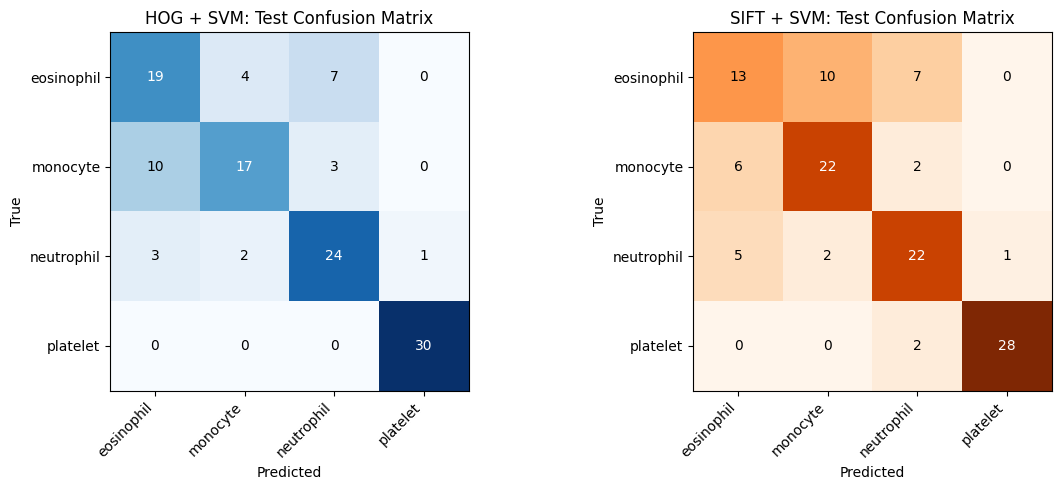

In [106]:
from sklearn.metrics import ConfusionMatrixDisplay

# Extract test features
X_test_hog_feats = np.array([hog_feat(im) for im in X_test])
X_test_sift_feats = np.array([sift_feat(im) for im in X_test])

# Get predictions
y_pred_hog = hog_model.predict(X_test_hog_feats)
y_pred_sift = sift_model.predict(X_test_sift_feats)

# Compute confusion matrices
cm_hog_test = confusion_matrix(y_test, y_pred_hog)
cm_sift_test = confusion_matrix(y_test, y_pred_sift)

# Plot side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# HOG + SVM Confusion Matrix
im1 = axes[0].imshow(cm_hog_test, cmap="Blues")
axes[0].set_title("HOG + SVM: Test Confusion Matrix")
axes[0].set_xticks(range(4))
axes[0].set_yticks(range(4))
axes[0].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
axes[0].set_yticklabels(CLASS_NAMES)
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, cm_hog_test[i, j], ha="center", va="center",
                     color="white" if cm_hog_test[i, j] > cm_hog_test.max() / 2 else "black")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

# SIFT + SVM Confusion Matrix
im2 = axes[1].imshow(cm_sift_test, cmap="Oranges")
axes[1].set_title("SIFT + SVM: Test Confusion Matrix")
axes[1].set_xticks(range(4))
axes[1].set_yticks(range(4))
axes[1].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
axes[1].set_yticklabels(CLASS_NAMES)
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, cm_sift_test[i, j], ha="center", va="center",
                     color="white" if cm_sift_test[i, j] > cm_sift_test.max() / 2 else "black")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.tight_layout()
plt.show()

## Q4(c) Was the prediction correct? (1 mark)
The code below reads the table and states which model actually lost more under each change, so the answer is tied to real outputs. Then write your three-sentence explanation in the markdown cell after it.

In [107]:
for col, label in [("Drop under rotation", "rotation"), ("Drop under noise", "noise")]:
    for m in drops.index:
        d = drops.loc[m, col]
        verb = "dropped" if d > 0 else "increased"
        print(f"{label}: {m} accuracy {verb} by {abs(d)*100:.2f} percentage points (about {abs(d)*120:.0f} of 120 images)")

rotation: HOG + SVM accuracy increased by 2.50 percentage points (about 3 of 120 images)
rotation: SIFT + SVM accuracy increased by 3.33 percentage points (about 4 of 120 images)
noise: HOG + SVM accuracy dropped by 50.00 percentage points (about 60 of 120 images)
noise: SIFT + SVM accuracy increased by 0.83 percentage points (about 1 of 120 images)


**Explanation (3 sentences) - complete after running, using the numbers printed above:**

My prediction was only partly confirmed. Under rotation neither model lost accuracy (HOG went from 0.7500 to 0.7750 and SIFT from 0.7083 to 0.7417), and since these changes are only 3 to 4 images out of 120, the rotation prediction cannot be called clearly correct. Under noise my prediction was correct: HOG collapsed from 0.7500 to 0.2500 (all 120 noisy images were predicted as monocyte), while SIFT stayed almost unchanged (0.7083 to 0.7167), so grid-SIFT, which uses larger Gaussian-smoothed patches, was much more robust to noise than HOG’s small cells that work on raw pixel gradients.


# Q5. Short answers and AI log (3 marks)
## Q5(1) Concept questions
**(a) Why does HOG use block normalisation?**
Gradient magnitudes change with lighting and contrast, so the same structure can give very different histogram values in different parts of an image or in different images. Block normalisation rescales the histograms of each small group of cells (2x2 here) so the features describe the *shape* of the edges rather than how bright or contrasty the region is, which makes the features more stable and comparable. Overlapping blocks also let each cell be normalised in several contexts.

**(b) Why is it wrong to choose C using the test set?**
The test set is meant to be an unbiased estimate of how the model performs on completely new data. If we pick C by looking at test accuracy, the test data has influenced the model, so the reported accuracy becomes optimistic (it is "data leakage"/overfitting to the test set). We must choose C on the validation set and use the test set only once, at the very end.

## Q5(2) Which two classes were confused most?
**Answer:** Both models confused **eosinophil and monocyte** the most. In the validation confusion matrices, HOG had 4 eosinophils predicted as monocyte and 11 monocytes predicted as eosinophil (total 15), and SIFT had 6 and 7 (total 13). Both are large white cells of similar size, and eosinophils are mainly recognised by their red-orange granules while monocytes have a large kidney-shaped nucleus. Grayscale removes the colour cue, so only intensity and texture remain, which are similar for these two classes, and this makes them harder to separate.
### Addendum: Noisy HOG Prediction Check
The printed distribution `[0 120 0 0]` shows that all 120 noisy test images were predicted as one class (monocyte), so accuracy was 30/120 = 0.25, which is chance level for 4 balanced classes. A likely reason is that noise adds random gradients in every HOG cell, so the noisy features move far away from the training features and the linear SVM sends every image to the same class.

In [108]:
def most_confused(cm, tag):
    off = cm.copy().astype(int); np.fill_diagonal(off, 0)
    # combine both directions so we get an unordered pair
    pair_counts = {}
    for i in range(4):
        for j in range(i + 1, 4):
            pair_counts[(i, j)] = off[i, j] + off[j, i]
    (i, j), n = max(pair_counts.items(), key=lambda kv: kv[1])
    print(f"{tag}: most confused pair = {CLASS_NAMES[i]} <-> {CLASS_NAMES[j]} "
          f"({off[i,j]} {CLASS_NAMES[i]}->{CLASS_NAMES[j]}, {off[j,i]} {CLASS_NAMES[j]}->{CLASS_NAMES[i]}, total {n})")

most_confused(hog_cm, "HOG+SVM")
most_confused(sift_cm, "SIFT+SVM")

# Diagnostic step: check distribution of noisy predictions
F_noisy = np.array([hog_feat(im) for im in X_test_noisy])
noisy_preds = hog_model.predict(F_noisy)
print(f"\nDistribution of HOG predictions on noisy test set: {np.bincount(noisy_preds, minlength=4)}")

HOG+SVM: most confused pair = eosinophil <-> monocyte (4 eosinophil->monocyte, 11 monocyte->eosinophil, total 15)
SIFT+SVM: most confused pair = eosinophil <-> monocyte (6 eosinophil->monocyte, 7 monocyte->eosinophil, total 13)

Distribution of HOG predictions on noisy test set: [  0 120   0   0]


## Q5(3) AI log
> The student should edit this to describe what they truly did and checked. The table below is a draft that matches this notebook.

| Prompt (one line) | What I changed | How I checked it was correct |
|---|---|---|
| Write a step-by-step notebook for the HOG vs SIFT blood-cell lab (reg 030: seed 30, HOG 8x8, SIFT 4x4 grid). | Changed the loader to medmnist size=64 as the exam requires and re-ran the whole notebook; wrote my own Q4(c), Q5 answers and the noisy-HOG check from my outputs. | Printed shapes and class counts (400/120/120), asserted HOG length 8100 and SIFT length 2048 against my hand calculations, checked the pictures, and chose C only on validation.|